<a href="https://colab.research.google.com/github/Israr-Hussain7/Image-Processing-Using-OpenCV/blob/main/Heart_Disease_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

from google.colab import files

# Upload Excel file
uploaded = files.upload()

# Get uploaded filename
filename = list(uploaded.keys())[0]

# Read Excel dataset
df = pd.read_excel(filename)

# Display first 5 rows
df.head()


Saving heart_disease_data.csv to heart_disease_data.csv


NameError: name 'pd' is not defined

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [3]:

from google.colab import files

# Upload CSV file
uploaded = files.upload()

# Get uploaded filename
filename = list(uploaded.keys())[0]

# Read CSV dataset
df = pd.read_csv(filename)

# Display first 5 rows
df.head()


Saving heart_disease_data.csv to heart_disease_data (1).csv


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [4]:

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe())


Dataset Shape: (303, 14)

Column Names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB

Missing Values:
age         0
sex

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [5]:

# Display first 10 rows
display(df.head(10))

# Display last 5 rows
display(df.tail())

# Check dataset shape
print("Total Rows and Columns:", df.shape)

# Check column names
print("\nDataset Columns:")
print(df.columns.tolist())

# Check data types
print("\nData Types:")
print(df.dtypes)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
5,57,1,0,140,192,0,1,148,0,0.4,1,0,1,1
6,56,0,1,140,294,0,0,153,0,1.3,1,0,2,1
7,44,1,1,120,263,0,1,173,0,0.0,2,0,3,1
8,52,1,2,172,199,1,1,162,0,0.5,2,0,3,1
9,57,1,2,150,168,0,1,174,0,1.6,2,0,2,1


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0
302,57,0,1,130,236,0,0,174,0,0.0,1,1,2,0


Total Rows and Columns: (303, 14)

Dataset Columns:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Data Types:
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64
dtype: object

Missing Values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Duplicate Rows: 1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


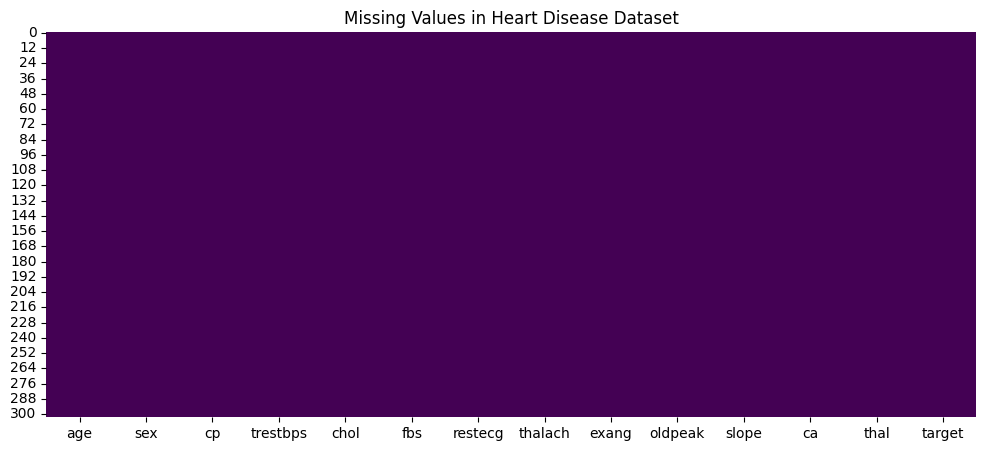

In [6]:


# Dataset information
df.info()

# Statistical summary
display(df.describe())

# Visualize missing values
plt.figure(figsize=(12, 5))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title("Missing Values in Heart Disease Dataset")
plt.show()



In [7]:

# Check duplicate records
print("Total Duplicate Rows:", df.duplicated().sum())

# Remove duplicate records if any
df = df.drop_duplicates()

# Check updated dataset shape
print("Updated Dataset Shape:", df.shape)


Total Duplicate Rows: 1
Updated Dataset Shape: (302, 14)


In [8]:

print("Dataset Columns:")
for column in df.columns:
    print(column)


Dataset Columns:
age
sex
cp
trestbps
chol
fbs
restecg
thalach
exang
oldpeak
slope
ca
thal
target


In [9]:

# Display all column names
print("Total Columns:", len(df.columns))

print("\nColumn Names:")
print(df.columns.tolist())

# Display first 5 records
display(df.head())


Total Columns: 14

Column Names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [10]:

# Display unique values in each column
for col in df.columns:
    print(col, ":", df[col].unique())


age : [63 37 41 56 57 44 52 54 48 49 64 58 50 66 43 69 59 42 61 40 71 51 65 53
 46 45 39 47 62 34 35 29 55 60 67 68 74 76 70 38 77]
sex : [1 0]
cp : [3 2 1 0]
trestbps : [145 130 120 140 172 150 110 135 160 105 125 142 155 104 138 128 108 134
 122 115 118 100 124  94 112 102 152 101 132 148 178 129 180 136 126 106
 156 170 146 117 200 165 174 192 144 123 154 114 164]
chol : [233 250 204 236 354 192 294 263 199 168 239 275 266 211 283 219 340 226
 247 234 243 302 212 175 417 197 198 177 273 213 304 232 269 360 308 245
 208 264 321 325 235 257 216 256 231 141 252 201 222 260 182 303 265 309
 186 203 183 220 209 258 227 261 221 205 240 318 298 564 277 214 248 255
 207 223 288 160 394 315 246 244 270 195 196 254 126 313 262 215 193 271
 268 267 210 295 306 178 242 180 228 149 278 253 342 157 286 229 284 224
 206 167 230 335 276 353 225 330 290 172 305 188 282 185 326 274 164 307
 249 341 407 217 174 281 289 322 299 300 293 184 409 259 200 327 237 218
 319 166 311 169 187 176 241 131]
fbs :

Heart Disease Distribution:
target
1    164
0    138
Name: count, dtype: int64

Percentage Distribution:
target
1    54.304636
0    45.695364
Name: proportion, dtype: float64


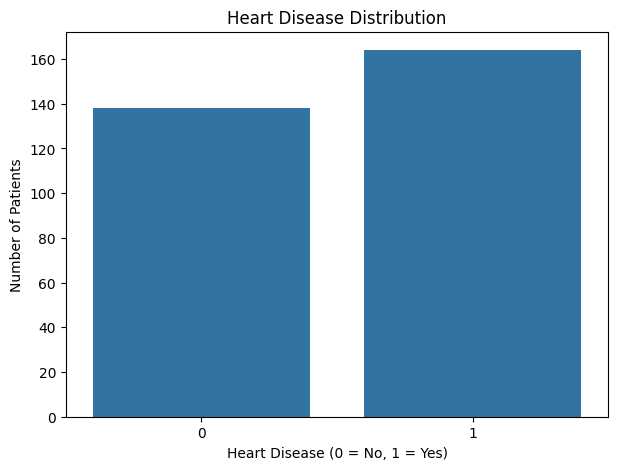

In [11]:

# Count target values
print("Heart Disease Distribution:")
print(df['target'].value_counts())

# Convert counts into percentages
print("\nPercentage Distribution:")
print(df['target'].value_counts(normalize=True) * 100)

# Visualize target distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='target')

plt.title('Heart Disease Distribution')
plt.xlabel('Heart Disease (0 = No, 1 = Yes)')
plt.ylabel('Number of Patients')

plt.show()


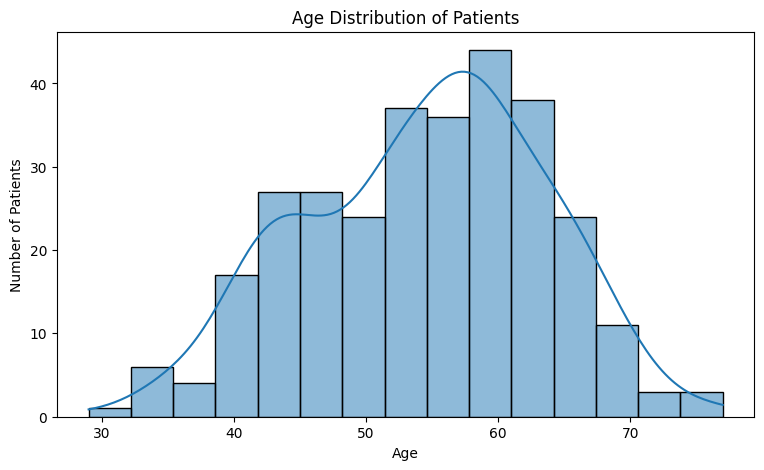

In [12]:

plt.figure(figsize=(9, 5))

sns.histplot(data=df, x='age', bins=15, kde=True)

plt.title('Age Distribution of Patients')
plt.xlabel('Age')
plt.ylabel('Number of Patients')

plt.show()


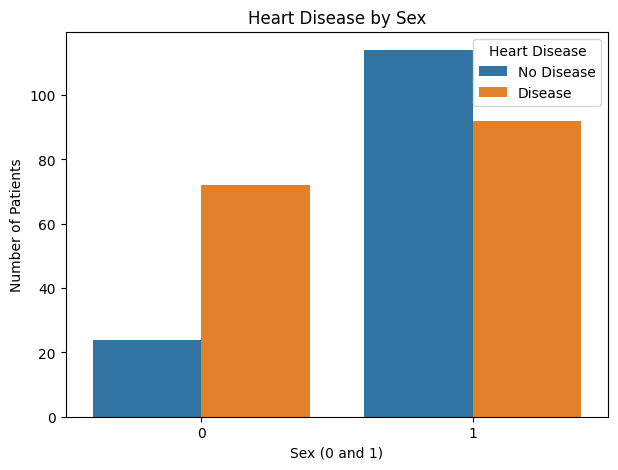

In [13]:

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='sex', hue='target')

plt.title('Heart Disease by Sex')
plt.xlabel('Sex (0 and 1)')
plt.ylabel('Number of Patients')

plt.legend(
    title='Heart Disease',
    labels=['No Disease', 'Disease']
)

plt.show()


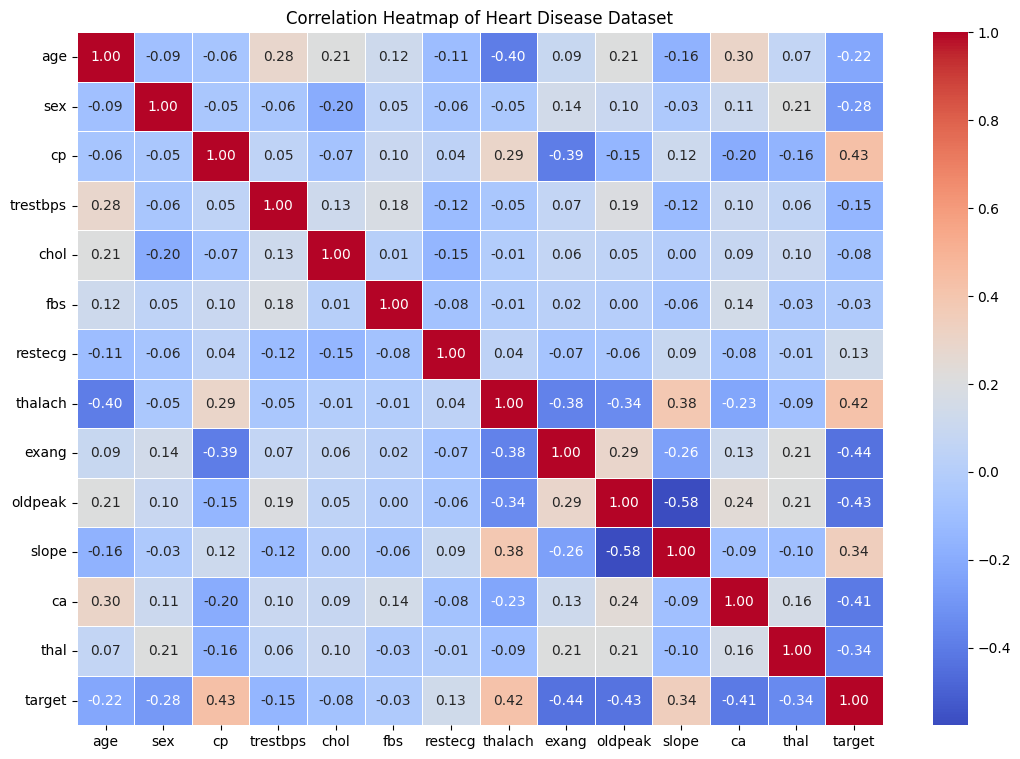

In [14]:

plt.figure(figsize=(13, 9))

correlation = df.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Heart Disease Dataset')

plt.show()


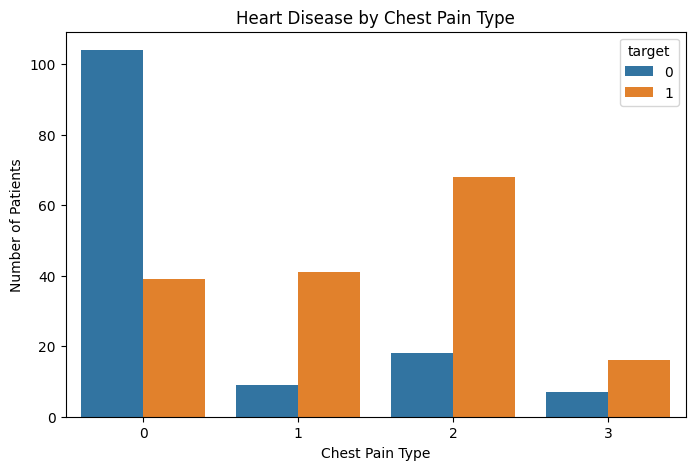

In [15]:

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='cp', hue='target')

plt.title('Heart Disease by Chest Pain Type')
plt.xlabel('Chest Pain Type')
plt.ylabel('Number of Patients')

plt.show()


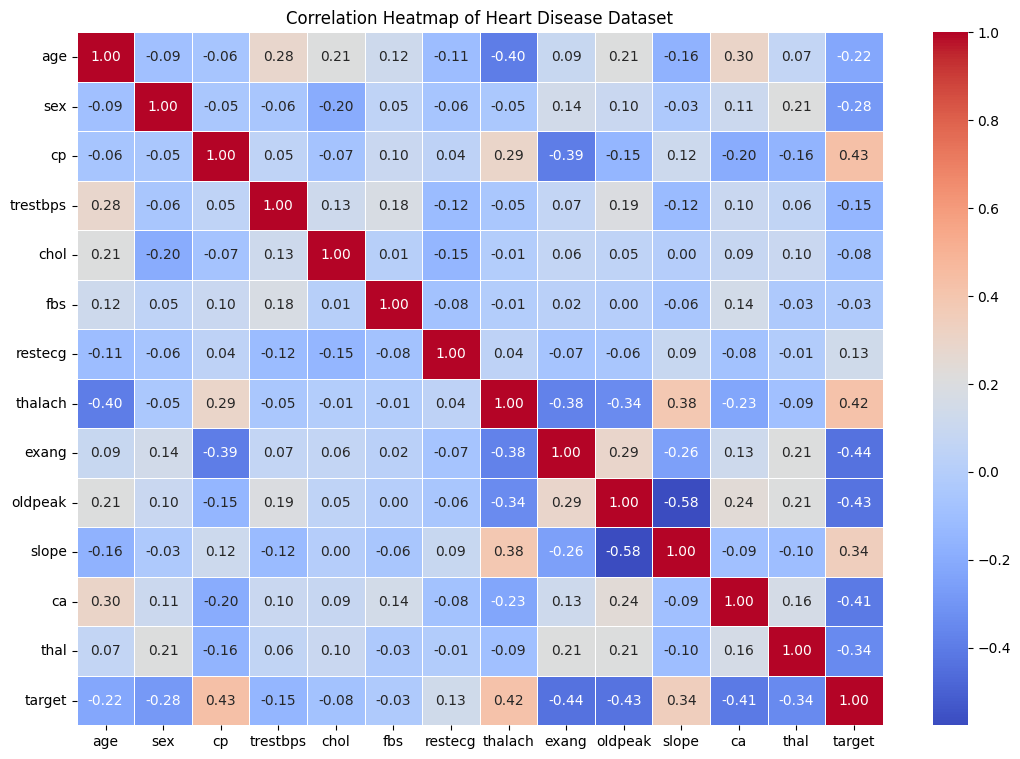

In [16]:

plt.figure(figsize=(13, 9))

correlation = df.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Heart Disease Dataset')
plt.show()


In [17]:

# Separate independent variables
X = df.drop('target', axis=1)

# Separate dependent variable
y = df['target']

# Display shapes
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

# Display first 5 feature records
display(X.head())

# Display target values
display(y.head())


Features Shape: (302, 13)
Target Shape: (302,)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2


,target
0,1
1,1
2,1
3,1
4,1


In [18]:

from sklearn.model_selection import train_test_split

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)


Training Features: (241, 13)
Testing Features: (61, 13)
Training Target: (241,)
Testing Target: (61,)


In [19]:

from sklearn.preprocessing import StandardScaler

# Create scaler
scaler = StandardScaler()

# Fit scaler on training data only
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data
X_test_scaled = scaler.transform(X_test)

print("Feature Scaling Completed Successfully!")

print("Scaled Training Data:", X_train_scaled.shape)
print("Scaled Testing Data:", X_test_scaled.shape)


Feature Scaling Completed Successfully!
Scaled Training Data: (241, 13)
Scaled Testing Data: (61, 13)


In [20]:

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

print("All Machine Learning Models Imported Successfully!")


All Machine Learning Models Imported Successfully!


In [21]:

# Create machine learning models

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "SVM": SVC(
        probability=True,
        random_state=42
    )
}

print("Five Machine Learning Models Created Successfully!")


Five Machine Learning Models Created Successfully!


In [22]:

# Train all models

for name, model in models.items():

    model.fit(X_train_scaled, y_train)

    print(name, "Training Completed Successfully!")


Logistic Regression Training Completed Successfully!
Decision Tree Training Completed Successfully!
Random Forest Training Completed Successfully!
KNN Training Completed Successfully!
SVM Training Completed Successfully!


In [23]:

from sklearn.metrics import accuracy_score

# Store model results
model_results = []

for name, model in models.items():

    # Make predictions
    y_pred = model.predict(X_test_scaled)

    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred)

    model_results.append({
        "Model": name,
        "Accuracy": accuracy * 100
    })

# Create results dataframe
results_df = pd.DataFrame(model_results)

# Display results
results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
)

display(results_df)


,Model,Accuracy
4,SVM,83.606557
3,KNN,80.327869
0,Logistic Regression,78.688525
2,Random Forest,78.688525
1,Decision Tree,72.131148


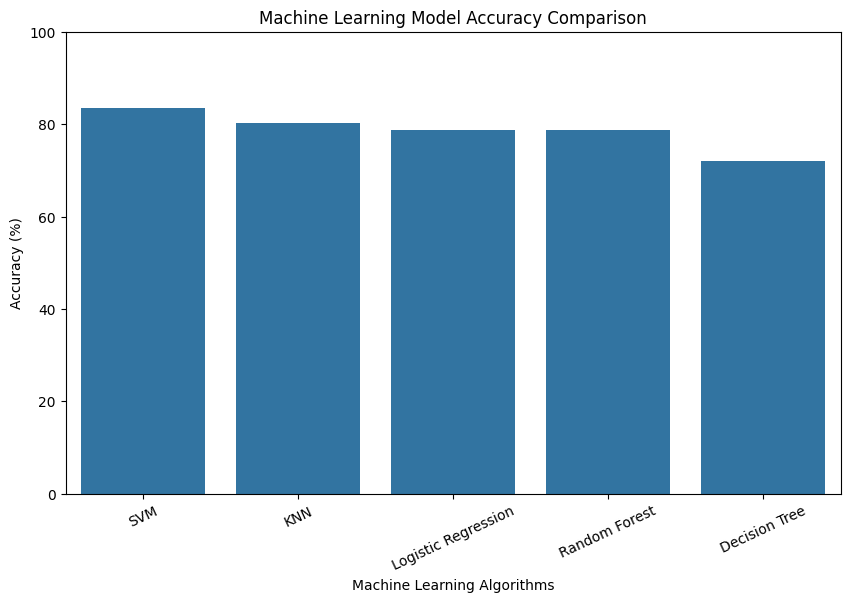

In [24]:

plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Machine Learning Model Accuracy Comparison")
plt.xlabel("Machine Learning Algorithms")
plt.ylabel("Accuracy (%)")

plt.xticks(rotation=25)
plt.ylim(0, 100)

plt.show()


In [25]:

from sklearn.metrics import classification_report

for name, model in models.items():

    print("\n================================")
    print("Model:", name)
    print("================================")

    y_pred = model.predict(X_test_scaled)

    print(classification_report(
        y_test,
        y_pred,
        target_names=['No Disease', 'Heart Disease'],
        zero_division=0
    ))



Model: Logistic Regression
               precision    recall  f1-score   support

   No Disease       0.83      0.68      0.75        28
Heart Disease       0.76      0.88      0.82        33

     accuracy                           0.79        61
    macro avg       0.79      0.78      0.78        61
 weighted avg       0.79      0.79      0.78        61


Model: Decision Tree
               precision    recall  f1-score   support

   No Disease       0.74      0.61      0.67        28
Heart Disease       0.71      0.82      0.76        33

     accuracy                           0.72        61
    macro avg       0.72      0.71      0.71        61
 weighted avg       0.72      0.72      0.72        61


Model: Random Forest
               precision    recall  f1-score   support

   No Disease       0.86      0.64      0.73        28
Heart Disease       0.75      0.91      0.82        33

     accuracy                           0.79        61
    macro avg       0.80      0.78      

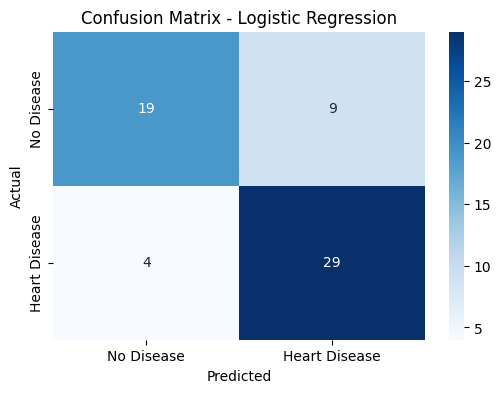

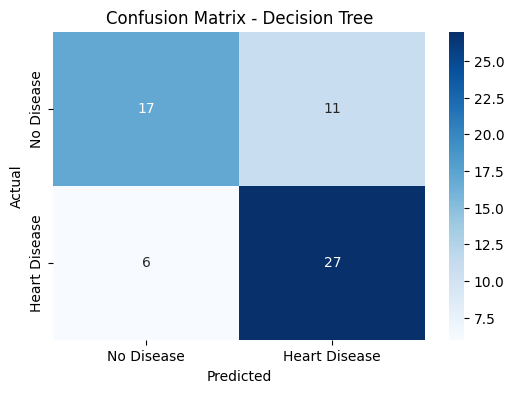

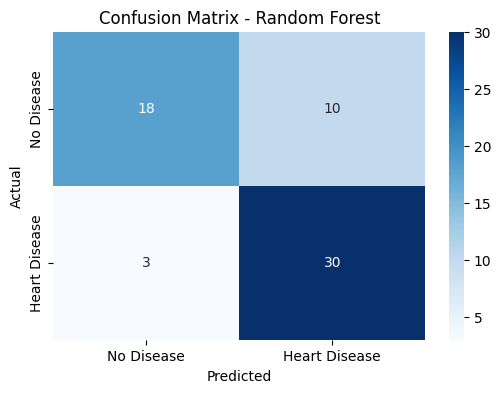

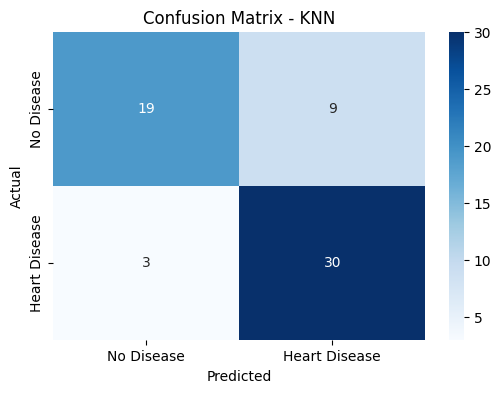

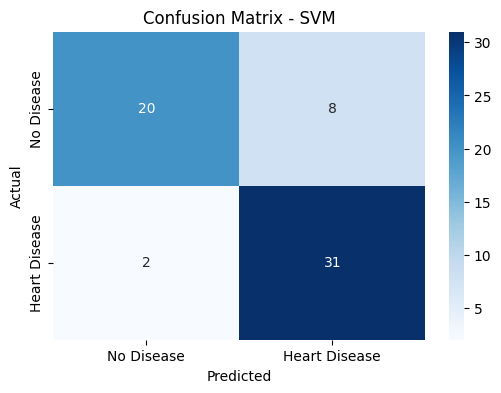

In [26]:

from sklearn.metrics import confusion_matrix

for name, model in models.items():

    y_pred = model.predict(X_test_scaled)

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(6, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['No Disease', 'Heart Disease'],
        yticklabels=['No Disease', 'Heart Disease']
    )

    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')

    plt.show()


In [27]:

from sklearn.metrics import roc_auc_score

auc_results = []

for name, model in models.items():

    y_probability = model.predict_proba(X_test_scaled)[:, 1]

    auc = roc_auc_score(y_test, y_probability)

    auc_results.append({
        'Model': name,
        'ROC-AUC': auc
    })

auc_df = pd.DataFrame(auc_results)

display(
    auc_df.sort_values(
        by='ROC-AUC',
        ascending=False
    )
)


,Model,ROC-AUC
4,SVM,0.880952
2,Random Forest,0.876623
3,KNN,0.867424
0,Logistic Regression,0.864719
1,Decision Tree,0.712662


In [28]:

from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Create SVM pipeline
svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', SVC(
        kernel='rbf',
        probability=True,
        random_state=42
    ))
])

# Stratified 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluation metrics
scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc'
}

# Perform cross-validation
cv_results = cross_validate(
    svm_pipeline,
    X,
    y,
    cv=cv,
    scoring=scoring
)

# Display results
for metric in scoring:
    scores = cv_results['test_' + metric]

    print(
        metric.upper(),
        ':',
        round(scores.mean(), 4),
        '+/-',
        round(scores.std(), 4)
    )


ACCURACY : 0.8109 +/- 0.0609
PRECISION : 0.7974 +/- 0.069
RECALL : 0.8847 +/- 0.0699
F1 : 0.8362 +/- 0.0503
ROC_AUC : 0.8874 +/- 0.065


In [29]:

# Train final SVM pipeline on complete dataset
final_model = svm_pipeline.fit(X, y)

print("Final SVM Model Trained Successfully!")


Final SVM Model Trained Successfully!


In [30]:

import joblib

# Save trained model
joblib.dump(final_model, 'heart_disease_model.pkl')

print("Model Saved Successfully!")


Model Saved Successfully!


In [31]:

from google.colab import files

files.download('heart_disease_model.pkl')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:


# Sample patient information

patient_data = pd.DataFrame([{
    'age': 55,
    'sex': 1,
    'cp': 2,
    'trestbps': 130,
    'chol': 250,
    'fbs': 0,
    'restecg': 1,
    'thalach': 150,
    'exang': 0,
    'oldpeak': 1.0,
    'slope': 1,
    'ca': 0,
    'thal': 2
}])

# Arrange features in correct order
patient_data = patient_data[X.columns]

# Predict
prediction = final_model.predict(patient_data)

probability = final_model.predict_proba(patient_data)[0]

print("--------------------------------")
print("HEART DISEASE PREDICTION")
print("--------------------------------")

if prediction[0] == 1:
    print("Prediction: Heart Disease Class")
else:
    print("Prediction: No Heart Disease Class")

print("Class 0 Probability:",
      round(probability[0] * 100, 2), "%")

print("Class 1 Probability:",
      round(probability[1] * 100, 2), "%")

print("--------------------------------")



--------------------------------
HEART DISEASE PREDICTION
--------------------------------
Prediction: Heart Disease Class
Class 0 Probability: 14.81 %
Class 1 Probability: 85.19 %
--------------------------------


In [37]:

import ipywidgets as widgets
from IPython.display import display, clear_output

# Create input fields
age_input = widgets.IntSlider(
    value=55, min=20, max=100, description='Age:'
)

sex_input = widgets.Dropdown(
    options=[('Female (0)', 0), ('Male (1)', 1)],
    value=1, description='Sex:'
)

cp_input = widgets.Dropdown(
    options=[0, 1, 2, 3], description='Chest Pain:'
)

trestbps_input = widgets.IntSlider(
    value=130, min=80, max=220, description='BP:'
)

chol_input = widgets.IntSlider(
    value=250, min=100, max=600, description='Cholesterol:'
)

fbs_input = widgets.Dropdown(
    options=[0, 1], description='FBS:'
)

restecg_input = widgets.Dropdown(
    options=[0, 1, 2], description='Rest ECG:'
)

thalach_input = widgets.IntSlider(
    value=150, min=60, max=220, description='Max HR:'
)

exang_input = widgets.Dropdown(
    options=[0, 1], description='Exercise Angina:'
)

oldpeak_input = widgets.FloatSlider(
    value=1.0, min=0, max=7, step=0.1,
    description='Oldpeak:'
)

slope_input = widgets.Dropdown(
    options=[0, 1, 2], description='Slope:'
)

ca_input = widgets.Dropdown(
    options=[0, 1, 2, 3, 4], description='CA:'
)

thal_input = widgets.Dropdown(
    options=[0, 1, 2, 3], description='Thal:'
)

# Prediction button
predict_button = widgets.Button(
    description='Predict Heart Disease',
    button_style='success',
    icon='check'
)

output = widgets.Output()

# Prediction function
def predict_heart_disease(b):

    with output:
        clear_output()

        patient = pd.DataFrame([{
            'age': age_input.value,
            'sex': sex_input.value,
            'cp': cp_input.value,
            'trestbps': trestbps_input.value,
            'chol': chol_input.value,
            'fbs': fbs_input.value,
            'restecg': restecg_input.value,
            'thalach': thalach_input.value,
            'exang': exang_input.value,
            'oldpeak': oldpeak_input.value,
            'slope': slope_input.value,
            'ca': ca_input.value,
            'thal': thal_input.value
        }])

        patient = patient[X.columns]

        prediction = final_model.predict(patient)[0]
        probability = final_model.predict_proba(patient)[0]

        print("HEART DISEASE PREDICTION")
        print("-----------------------------")

        if prediction == 1:
            print("Predicted Class: Heart Disease (1)")
        else:
            print("Predicted Class: No Heart Disease (0)")

        print(
            "Class 0 Probability:",
            round(probability[0] * 100, 2), "%"
        )

        print(
            "Class 1 Probability:",
            round(probability[1] * 100, 2), "%"
        )

        print("-----------------------------")
        print("Educational prediction only.")
        print("Not a medical diagnosis.")

predict_button.on_click(predict_heart_disease)

# Display interface
display(widgets.VBox([
    widgets.HTML("<h2>Heart Disease Prediction System</h2>"),
    age_input,
    sex_input,
    cp_input,
    trestbps_input,
    chol_input,
    fbs_input,
    restecg_input,
    thalach_input,
    exang_input,
    oldpeak_input,
    slope_input,
    ca_input,
    thal_input,
    predict_button,
    output
]))
